In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

import pandas as pd
import zipfile
import io
import urllib.request

url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

response = urllib.request.urlopen(url)

with zipfile.ZipFile(io.BytesIO(response.read())) as z:
    excel_file = next(
        name for name in z.namelist()
        if name.lower().endswith(".xlsx")
    )

    with z.open(excel_file) as file:
        df = pd.read_excel(file)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:

# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Convert InvoiceDate to datetime
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

# Remove rows without CustomerID
df = df.dropna(subset=["CustomerID", "InvoiceDate"])

# Remove cancelled invoices
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

# Keep only positive quantity and price
df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

# Calculate total sales
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

print("\nDataset after cleaning:")
print("Rows:", df.shape[0])
print("Unique customers:", df["CustomerID"].nunique())

display(df.head())


Missing values before cleaning:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Dataset after cleaning:
Rows: 397884
Unique customers: 4338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [ ]:

# Reference date: latest invoice date + 1 day
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calculate RFM for each customer
rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x:
             (reference_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalAmount", "sum")
)

# Keep valid customer records
rfm = rfm[
    (rfm["Frequency"] > 0) &
    (rfm["Monetary"] > 0)
].copy()

print("RFM analysis completed!")
print("Number of customers:", len(rfm))

display(rfm.head(10))


RFM analysis completed!
Number of customers: 4338


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40
12352.0,36,8,2506.04
12353.0,204,1,89.00
12354.0,232,1,1079.40
12355.0,214,1,459.40


In [ ]:

import numpy as np
from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

# Reduce skew in RFM values
rfm_log = np.log1p(
    rfm[["Recency", "Frequency", "Monetary"]]
)

# Scale features to comparable ranges
scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm_log)

print("Feature scaling completed!")
print("Scaled data shape:", X_scaled.shape)

display(pd.DataFrame(
    X_scaled,
    columns=["Recency", "Frequency", "Monetary"]
).head())


Feature scaling completed!
Scaled data shape: (4338, 3)


,Recency,Frequency,Monetary
0,1.461993,-0.955214,3.706225
1,-2.038734,1.074425,1.411843
2,0.373104,0.386304,0.716489
3,-0.623086,-0.955214,0.698739
4,1.424558,-0.955214,-0.618962


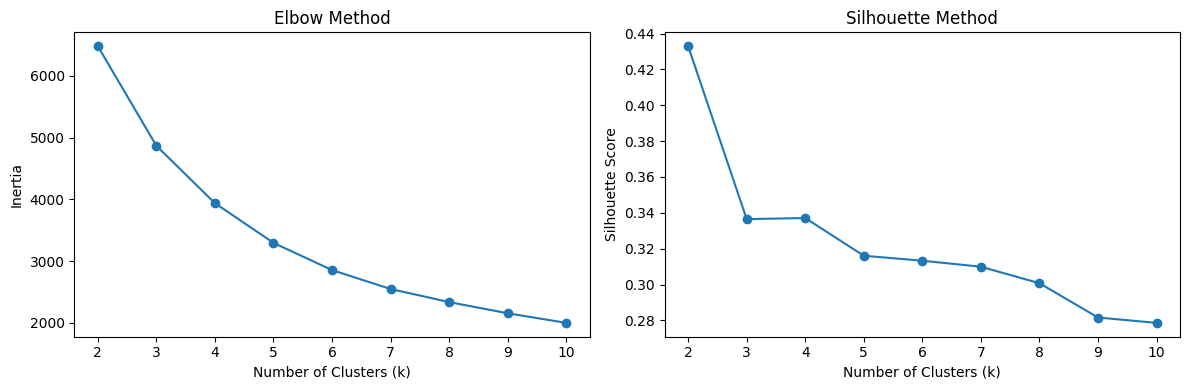

In [ ]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

inertias = []
silhouette_scores = []

# Test cluster counts from 2 to 10
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

# Plot both evaluation methods
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.subplot(1, 2, 2)
plt.plot(list(k_values), silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Method")

plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd
from sklearn.cluster import KMeans

# Find the k with the highest silhouette score
score_table = pd.DataFrame({
    "k": list(k_values),
    "Silhouette_Score": silhouette_scores,
    "Inertia": inertias
})

display(score_table.round(4))

best_k = int(
    score_table.loc[
        score_table["Silhouette_Score"].idxmax(), "k"
    ]
)

print("Selected number of clusters:", best_k)

# Train final K-Means model
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(X_scaled)

print("Final clustering completed!")
print("\nCustomers in each cluster:")
print(rfm["Cluster"].value_counts().sort_index())

print(
    "\nFinal Silhouette Score:",
    round(silhouette_score(X_scaled, rfm["Cluster"]), 4)
)

display(rfm.head(10))


,k,Silhouette_Score,Inertia
0,2,0.4329,6481.2253
1,3,0.3365,4867.8466
2,4,0.3371,3938.5100
3,5,0.3161,3295.9763
4,6,0.3133,2855.0112
5,7,0.3100,2548.9143
6,8,0.3008,2336.7775
7,9,0.2817,2155.6482
8,10,0.2787,1999.9033


Selected number of clusters: 2
Final clustering completed!

Customers in each cluster:
Cluster
0    2671
1    1667
Name: count, dtype: int64

Final Silhouette Score: 0.4329


,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346.0,326,1,77183.60,1
12347.0,2,7,4310.00,1
12348.0,75,4,1797.24,1
12349.0,19,1,1757.55,0
12350.0,310,1,334.40,0
12352.0,36,8,2506.04,1
12353.0,204,1,89.00,0
12354.0,232,1,1079.40,0
12355.0,214,1,459.40,0


In [ ]:

# Summarize each customer cluster
cluster_summary = rfm.groupby("Cluster").agg(
    Total_Customers=("Recency", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

# Calculate percentage of customers in each cluster
cluster_summary["Customer_Percentage"] = (
    cluster_summary["Total_Customers"] /
    len(rfm) * 100
).round(2)

print("Customer Cluster Summary:")
display(cluster_summary)


Customer Cluster Summary:


,Total_Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Customer_Percentage
Cluster,,,,,
0,2671,134.14,1.67,497.74,61.57
1,1667,25.88,8.44,4548.26,38.43


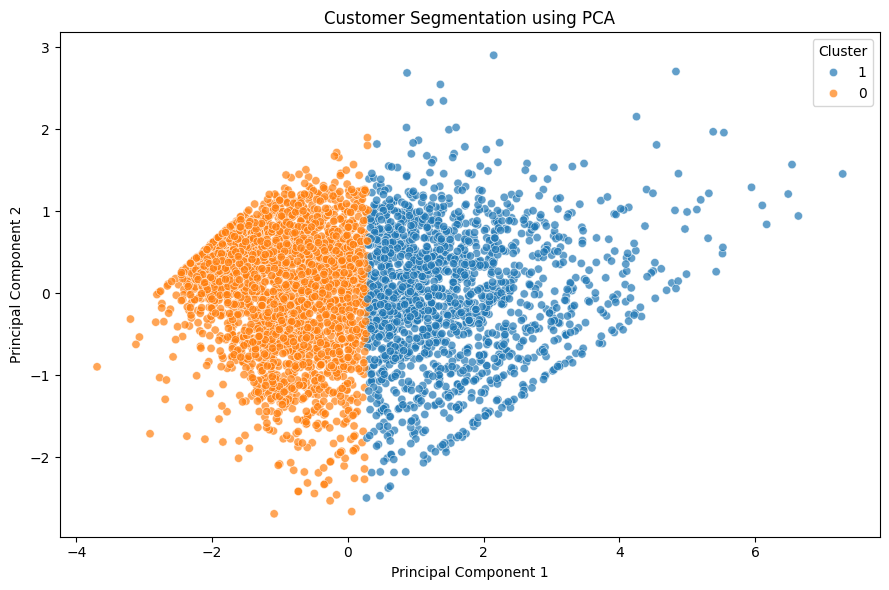

Variance represented by 2D PCA: 93.86 %


In [ ]:

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

pca = PCA(n_components=2)
pca_data = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    pca_data,
    columns=["PC1", "PC2"]
)
pca_df["Cluster"] = rfm["Cluster"].astype(str).values

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    alpha=0.7
)

plt.title("Customer Segmentation using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

print(
    "Variance represented by 2D PCA:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


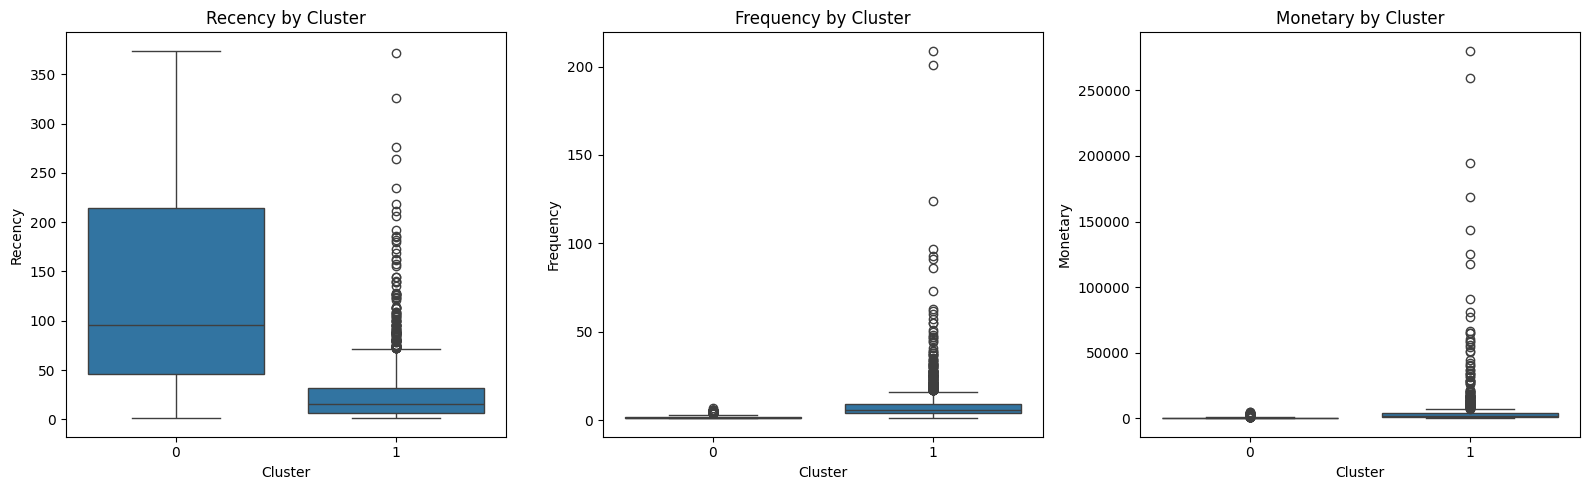

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, feature in zip(
    axes, ["Recency", "Frequency", "Monetary"]
):
    sns.boxplot(
        data=rfm,
        x="Cluster",
        y=feature,
        ax=ax
    )
    ax.set_title(f"{feature} by Cluster")

plt.tight_layout()
plt.show()


In [ ]:

overall = rfm[
    ["Recency", "Frequency", "Monetary"]
].mean()

def assign_persona(row):
    recent = row["Avg_Recency"] < overall["Recency"]
    frequent = row["Avg_Frequency"] > overall["Frequency"]
    high_spend = row["Avg_Monetary"] > overall["Monetary"]

    if recent and frequent and high_spend:
        return "Loyal High-Value Customers"
    elif not recent and not frequent:
        return "At-Risk / Inactive Customers"
    elif frequent:
        return "Frequent Customers"
    elif high_spend:
        return "High-Spending Customers"
    elif recent:
        return "Recently Active Customers"
    else:
        return "Occasional Customers"

persona_summary = cluster_summary.copy()
persona_summary["Persona"] = persona_summary.apply(
    assign_persona, axis=1
)

display(persona_summary)


,Total_Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Customer_Percentage,Persona
Cluster,,,,,,
0,2671,134.14,1.67,497.74,61.57,At-Risk / Inactive Customers
1,1667,25.88,8.44,4548.26,38.43,Loyal High-Value Customers


In [ ]:

# Save customer-level RFM and cluster labels
rfm.to_csv("customer_rfm_clusters.csv", index=True)

# Save cluster profiles
cluster_summary.to_csv("cluster_profile_summary.csv")

# Save customer personas
persona_summary.to_csv("customer_persona_summary.csv")

print("All output files saved successfully!")
print("1. customer_rfm_clusters.csv")
print("2. cluster_profile_summary.csv")
print("3. customer_persona_summary.csv")


All output files saved successfully!
1. customer_rfm_clusters.csv
2. cluster_profile_summary.csv
3. customer_persona_summary.csv
